(19968, 81)

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


DatetimeIndex(['2021-01-04', '2021-01-11', '2021-01-18', '2021-01-25',
               '2021-02-01', '2021-02-08', '2021-02-15', '2021-02-22',
               '2021-03-01', '2021-03-08',
               ...
               '2024-10-21', '2024-10-28', '2024-11-04', '2024-11-11',
               '2024-11-18', '2024-11-25', '2024-12-02', '2024-12-09',
               '2024-12-16', '2024-12-23'],
              dtype='datetime64[us]', name='date_semaine', length=208, freq='W-MON')


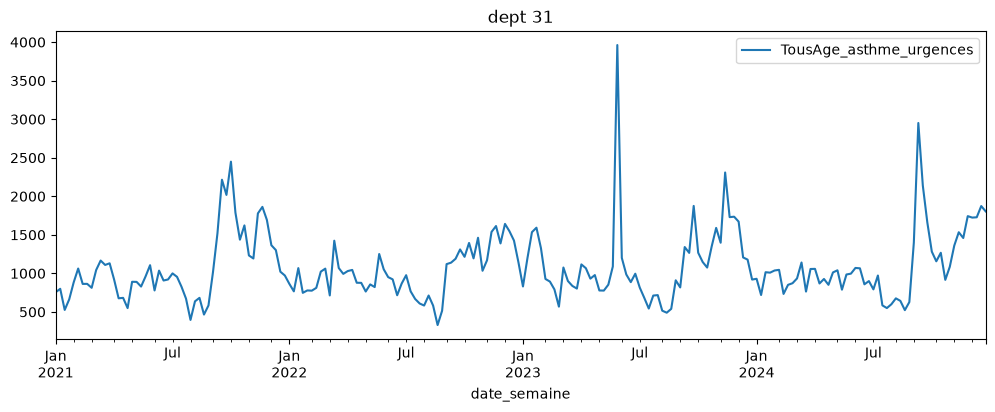

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv('../data/final_metropole/Merge_final_2.csv',dtype={"code_dept": str})

display(df.shape)
display(df.head())

s31 = df.loc[df["code_dept"] == "31"]
dates = pd.to_datetime(s31["date_semaine"] + "-1", format="%G-S%V-%u")
s31 = s31.set_index(dates)[["TousAge_asthme_urgences"]]
s31 = s31.asfreq('W-MON')     
print(s31.index)

s31.plot(figsize=(12, 4));   
plt.title("dept 31");

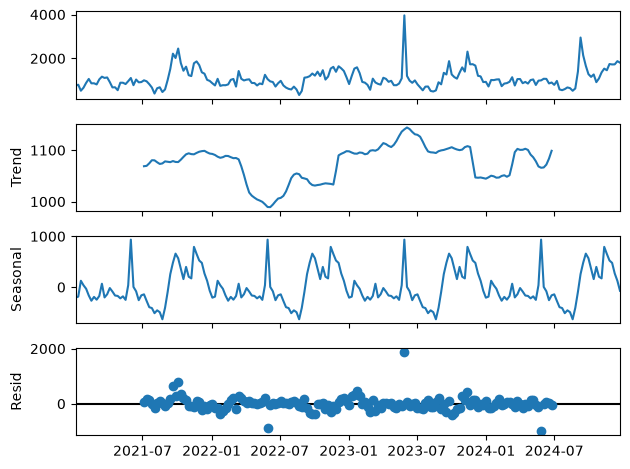

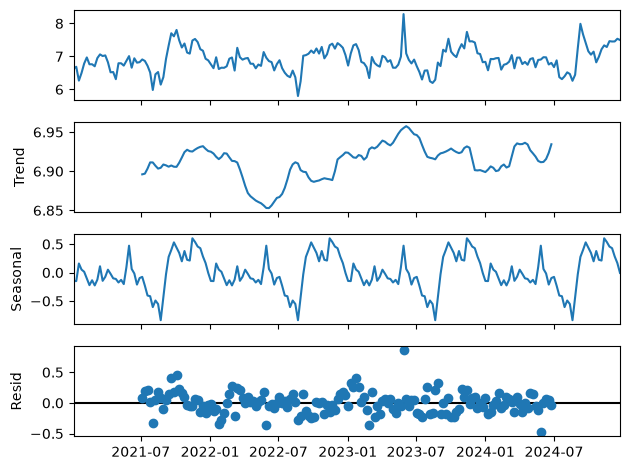

In [36]:
from statsmodels.tsa.seasonal import seasonal_decompose

res = seasonal_decompose(s31)
res.plot()
plt.show()

res = seasonal_decompose(np.log(s31))
res.plot()
plt.show()

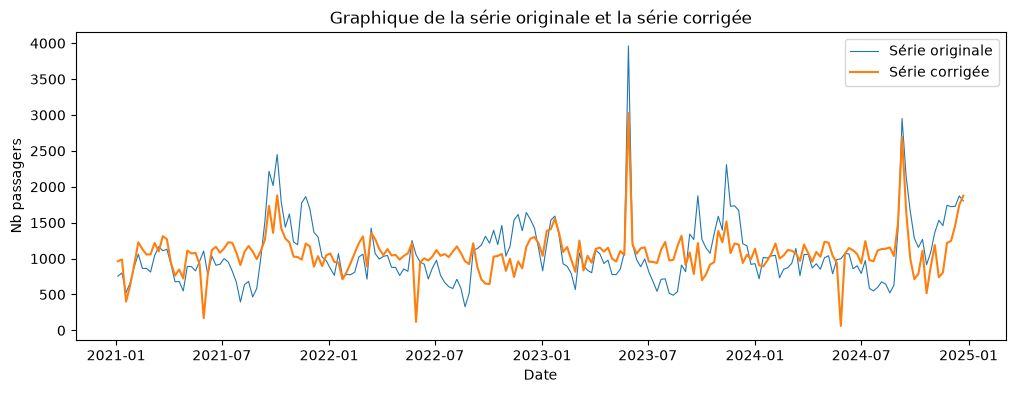

In [37]:
mult = seasonal_decompose(s31)

cvs = s31['TousAge_asthme_urgences'] - mult.seasonal

plt.figure(figsize=(12, 4))
plt.plot(s31, label='Série originale', linewidth=0.8)
plt.plot(cvs, label='Série corrigée')
plt.title('Graphique de la série originale et la série corrigée')
plt.xlabel('Date')
plt.ylabel('Nb passagers')
plt.legend()
plt.show();

In [38]:
s31_log = np.log(s31)            # transformation point par point, sans fuite entre périodes

annee = s31_log.index.year
train = s31_log[annee <= 2022]
val   = s31_log[annee == 2023]
test  = s31_log[annee == 2024]
print(len(train), len(val), len(test))


104 52 52


brute               0.0041
diff(1)             0.0049
diff(52)            0.0001
diff(1)+diff(52)    0.0000
Name: p ADF, dtype: float64


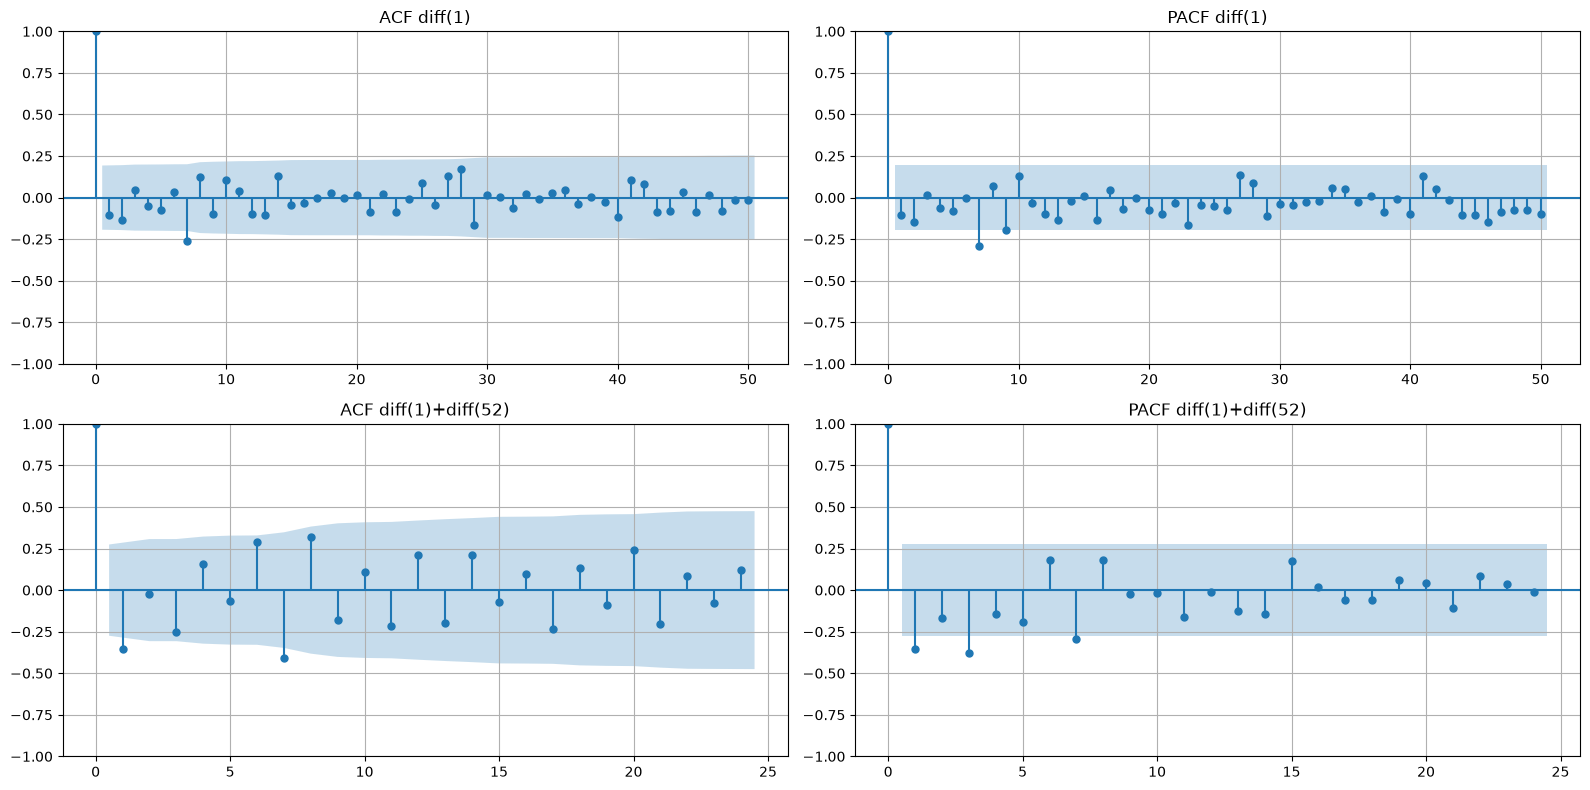

In [39]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

S = 52
y = s31_log["TousAge_asthme_urgences"].asfreq("W-MON")        # série en log : diagnostics et modèle
y_train = y[y.index.year <= 2022]

y_brut = s31["TousAge_asthme_urgences"].asfreq("W-MON")       # AJOUT : série d'origine, pour les scores

transfos = {
    "brute":           y_train,
    "diff(1)":         y_train.diff(1),
    "diff(52)":        y_train.diff(S),
    "diff(1)+diff(52)": y_train.diff(1).diff(S),
}
print(pd.Series({k: adfuller(v.dropna())[1] for k, v in transfos.items()}, name="p ADF").round(4))

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for row, (nom, serie) in enumerate([("diff(1)", y_train.diff(1)),
                                    ("diff(1)+diff(52)", y_train.diff(1).diff(S))]):
    s = serie.dropna()
    nlags = min(50, len(s) // 2 - 1)
    plot_acf(s, lags=nlags, ax=axes[row, 0], title=f"ACF {nom}")
    plot_pacf(s, lags=nlags, ax=axes[row, 1], title=f"PACF {nom}", method="ywm")
    for ax in axes[row]:
        ax.grid()
plt.tight_layout()
plt.show()

In [22]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

y = np.log(y_brut)                                         # échelle log, utilisée par one_step
y_train = y[y.index.year <= 2022]                          # log, pour ADF / ACF / PACF
y_val   = y_brut[y_brut.index.year == 2023]  

def one_step(order, sorder=(0, 0, 0, 0), fit_last_year=2022, eval_year=2023):
    """Estime le modèle sur les années y_train
    Renvoie le modèle ajusté et les prévisions à t+1 pour chaque semaine de y_eval"""
    trend = "c" if (order[1] == 0 and sorder[1] == 0) else "n"
    fit_m  = y.index.year <= fit_last_year
    hist_m = y.index.year <= eval_year
    res = SARIMAX(y[fit_m], order=order, seasonal_order=sorder,
                  trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(y[hist_m])                # mêmes paramètres, série prolongée
    start = y.index[y.index.year == eval_year][0]
    pred = res_ext.get_prediction(start=start)    # prévision à un pas (observations jusqu'à t-1)
    return res, pred

def scores(y_true, y_pred):
    m = y_true.notna() & y_pred.notna()
    return {"R2":   r2_score(y_true[m], y_pred[m]),
            "MAE":  mean_absolute_error(y_true[m], y_pred[m]),
            "RMSE": root_mean_squared_error(y_true[m], y_pred[m])}

In [23]:
import itertools, warnings
warnings.filterwarnings("ignore")   # SARIMAX émet beaucoup d'avertissements de convergence

# MODIF : observations 2023 sur l'échelle d'origine (le modèle, lui, travaille sur y = log)
y_val = y_brut[y_brut.index.year == 2023]

results = []
for d, p, q, P, Q in itertools.product([0, 1], [0, 1], [0, 1], [0, 1], [0, 1]):
    order, sorder = (p, d, q), (P, 0, Q, 52)          # D = 0
    res, pred = one_step(order, sorder)               # ajustement 2021-2022 (log), prévisions t+1 sur 2023
    m = scores(y_val, np.exp(pred.predicted_mean))    # MODIF : retour à l'échelle d'origine
    results.append([order, sorder, res.bic, m["R2"], m["MAE"], m["RMSE"]])

# Baselines sur la même cible, échelle d'origine, sans aucune donnée de 2023
annee = y_brut.index.year
sem = y_brut.index.isocalendar().week
profil = y_brut[annee <= 2022].groupby(sem[annee <= 2022]).mean()      # MODIF : y_brut
bases = {
    "persistance":       y_brut.shift(1)[annee == 2023],                # MODIF : y_brut
    "profil saisonnier": pd.Series(sem[annee == 2023].map(profil).values, index=y_val.index),
}
for nom, bp in bases.items():
    m = scores(y_val, bp)
    results.append([nom, "-", np.nan, m["R2"], m["MAE"], m["RMSE"]])

grid = pd.DataFrame(results, columns=["order", "sorder", "BIC", "R2", "MAE", "RMSE"])
grid = grid.sort_values("RMSE").reset_index(drop=True)   # classement sur RMSE

# 10 meilleurs modèles + baselines, même si elles sont plus bas dans le classement
est_base = grid["order"].isin(bases.keys())
display(grid[(grid.index < 10) | est_base].round(3))

,order,sorder,BIC,R2,MAE,RMSE
0,profil saisonnier,-,NaN,0.167,282.762,498.451
1,"(0, 0, 0)","(1, 0, 0, 52)",56.508,0.146,276.493,504.716
2,"(1, 0, 1)","(1, 0, 0, 52)",6.728,0.119,265.627,512.443
3,"(0, 0, 1)","(1, 0, 0, 52)",26.385,0.111,268.554,514.726
4,"(1, 0, 0)","(1, 0, 0, 52)",2.260,0.099,267.251,518.352
5,"(1, 1, 1)","(1, 0, 0, 52)",5.149,0.085,270.221,522.465
6,"(1, 0, 0)","(1, 0, 1, 52)",6.859,0.078,267.487,524.379
7,"(1, 0, 1)","(0, 0, 1, 52)",6.616,0.074,269.151,525.532
8,"(1, 0, 0)","(0, 0, 0, 52)",5.266,0.055,276.006,530.944
9,"(1, 0, 0)","(0, 0, 1, 52)",2.163,0.052,268.975,531.640
